# IT160IU — Data Mining (Fall 2026)
# Step 1: Data Pre-processing — Heart Disease Dataset

**Role:** Person 1 — Dataset & Pre-processing (Step 1, 20 pts)

**Deliverables of this notebook:**
1. Explore the raw dataset
2. Data Cleaning (duplicates, missing values)
3. Data Reduction (outliers, near-constant features, multicollinearity)
4. Data Transformation (attribute naming for Weka/ARFF)
5. Data Analysis (target distribution, feature–target relationships, statistical tests)
6. Train/Test split (stratified)
7. Export `cleaned_heart_disease.csv`, `train.arff`, `test.arff` for Person 2 (J48) and Person 3 (Random Forest + evaluation)

**Dataset:** `heart_disease.csv` (10,000 rows, 21 columns).

**Expected project layout** (this notebook lives in `code/src/`):
```
code/
├── src/
│   └── Preprocessing.ipynb   <- this notebook
├── lib/
│   └── weka.jar
├── dataset/
│   ├── heart_disease.csv          <- raw input (already here)
│   ├── cleaned_heart_disease.csv  <- written by this notebook
│   ├── train.arff                 <- written by this notebook
│   └── test.arff                  <- written by this notebook
└── models/
```
If your layout is different, just edit `DATA_PATH` and `OUT_DIR` below (both accept relative or absolute paths).

In [2]:
import os
import warnings
import numpy as np
import pandas as pd
from scipy import stats
from scipy.io import arff as arff_reader
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

In [3]:
# DATA_PATH accepts both a relative path and an absolute path, per the
# assignment requirement. Default assumes this notebook sits in code/src/
# and the raw CSV sits in code/dataset/ (sibling folder), per the project layout.
DATA_PATH = "../dataset/heart_disease.csv"

df = pd.read_csv(DATA_PATH)
df.head()

,Age,Gender,Blood Pressure,Cholesterol Level,Exercise Habits,Smoking,Family Heart Disease,Diabetes,BMI,High Blood Pressure,...,High LDL Cholesterol,Alcohol Consumption,Stress Level,Sleep Hours,Sugar Consumption,Triglyceride Level,Fasting Blood Sugar,CRP Level,Homocysteine Level,Heart Disease Status
0,56.0,Male,153.0,155.0,High,Yes,Yes,No,24.991591,Yes,...,No,High,Medium,7.633228,Medium,342.0,NaN,12.969246,12.387250,No
1,69.0,Female,146.0,286.0,High,No,Yes,Yes,25.221799,No,...,No,Medium,High,8.744034,Medium,133.0,157.0,9.355389,19.298875,No
2,46.0,Male,126.0,216.0,Low,No,No,No,29.855447,No,...,Yes,Low,Low,4.440440,Low,393.0,92.0,12.709873,11.230926,No
3,32.0,Female,122.0,293.0,High,Yes,Yes,No,24.130477,Yes,...,Yes,Low,High,5.249405,High,293.0,94.0,12.509046,5.961958,No
4,60.0,Male,166.0,242.0,Low,Yes,Yes,Yes,20.486289,Yes,...,No,Low,High,7.030971,High,263.0,154.0,10.381259,8.153887,No


## 1. Explore the Raw Dataset

In [4]:
print("Shape (rows, columns):", df.shape)

Shape (rows, columns): (10000, 21)


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Age                   9971 non-null   float64
 1   Gender                9981 non-null   str    
 2   Blood Pressure        9981 non-null   float64
 3   Cholesterol Level     9970 non-null   float64
 4   Exercise Habits       9975 non-null   str    
 5   Smoking               9975 non-null   str    
 6   Family Heart Disease  9979 non-null   str    
 7   Diabetes              9970 non-null   str    
 8   BMI                   9978 non-null   float64
 9   High Blood Pressure   9974 non-null   str    
 10  Low HDL Cholesterol   9975 non-null   str    
 11  High LDL Cholesterol  9974 non-null   str    
 12  Alcohol Consumption   7414 non-null   str    
 13  Stress Level          9978 non-null   str    
 14  Sleep Hours           9975 non-null   float64
 15  Sugar Consumption     9970 non-

In [6]:
# Numeric attributes summary
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,9971.0,49.296259,18.193970,18.000000,34.000000,49.000000,65.000000,80.000000
Blood Pressure,9981.0,149.757740,17.572969,120.000000,134.000000,150.000000,165.000000,180.000000
Cholesterol Level,9970.0,225.425577,43.575809,150.000000,187.000000,226.000000,263.000000,300.000000
BMI,9978.0,29.077269,6.307098,18.002837,23.658075,29.079492,34.520015,39.996954
Sleep Hours,9975.0,6.991329,1.753195,4.000605,5.449866,7.003252,8.531577,9.999952
Triglyceride Level,9974.0,250.734409,87.067226,100.000000,176.000000,250.000000,326.000000,400.000000
Fasting Blood Sugar,9978.0,120.142213,23.584011,80.000000,99.000000,120.000000,141.000000,160.000000
CRP Level,9974.0,7.472201,4.340248,0.003647,3.674126,7.472164,11.255592,14.997087
Homocysteine Level,9980.0,12.456271,4.323426,5.000236,8.723334,12.409395,16.140564,19.999037


In [7]:
# Categorical / nominal attributes summary
df.describe(include=['object', 'string']).T

,count,unique,top,freq
Gender,9981,2,Male,5003
Exercise Habits,9975,3,High,3372
Smoking,9975,2,Yes,5123
Family Heart Disease,9979,2,No,5004
Diabetes,9970,2,No,5018
High Blood Pressure,9974,2,Yes,5022
Low HDL Cholesterol,9975,2,Yes,5000
High LDL Cholesterol,9974,2,No,5036
Alcohol Consumption,7414,3,Medium,2500
Stress Level,9978,3,Medium,3387


**Observations:**
- 10,000 rows, 21 columns: 9 numeric attributes, 11 nominal attributes, and the target label `Heart Disease Status`.
- We define the two attribute groups explicitly below so every later step (plots, tests, ARFF export) uses a single, consistent reference instead of relying on pandas dtype inference, which can differ across pandas versions/environments.

In [8]:
NUMERIC_COLS = ['Age', 'Blood Pressure', 'Cholesterol Level', 'BMI', 'Sleep Hours',
                'Triglyceride Level', 'Fasting Blood Sugar', 'CRP Level', 'Homocysteine Level']

CATEGORICAL_COLS = ['Gender', 'Exercise Habits', 'Smoking', 'Family Heart Disease', 'Diabetes',
                     'High Blood Pressure', 'Low HDL Cholesterol', 'High LDL Cholesterol',
                     'Alcohol Consumption', 'Stress Level', 'Sugar Consumption']

TARGET_COL = 'Heart Disease Status'

print(f"{len(NUMERIC_COLS)} numeric columns, {len(CATEGORICAL_COLS)} categorical columns, 1 target column")

9 numeric columns, 11 categorical columns, 1 target column


## 2. Data Cleaning

### 2.1 Duplicate Rows

In [9]:
n_dup = df.duplicated().sum()
print(f"Fully duplicated rows: {n_dup}")

Fully duplicated rows: 0


No duplicated rows were found, so no rows need to be removed at this stage.

### 2.2 Missing Values

In [10]:
missing = df.isnull().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)
missing_table = pd.DataFrame({'missing_count': missing, 'missing_pct': missing_pct})
missing_table[missing_table['missing_count'] > 0]

,missing_count,missing_pct
Alcohol Consumption,2586,25.86
Diabetes,30,0.30
Sugar Consumption,30,0.30
Cholesterol Level,30,0.30
Age,29,0.29
Triglyceride Level,26,0.26
CRP Level,26,0.26
High LDL Cholesterol,26,0.26
High Blood Pressure,26,0.26
Low HDL Cholesterol,25,0.25


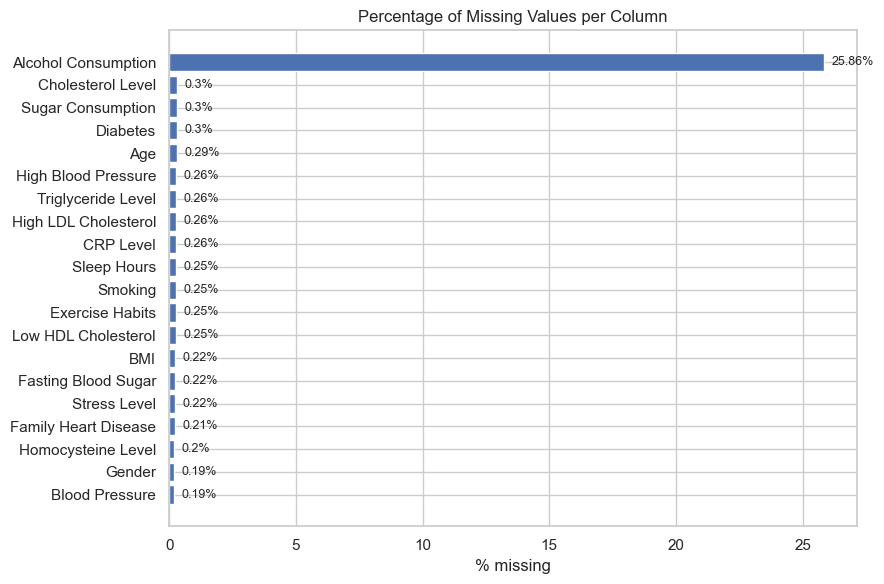

In [11]:
fig, ax = plt.subplots(figsize=(9, 6))
plot_data = missing_table[missing_table['missing_count'] > 0].sort_values('missing_pct')
ax.barh(plot_data.index, plot_data['missing_pct'], color='#4C72B0')
ax.set_xlabel('% missing')
ax.set_title('Percentage of Missing Values per Column')
for i, v in enumerate(plot_data['missing_pct']):
    ax.text(v + 0.3, i, f"{v}%", va='center', fontsize=9)
plt.tight_layout()
plt.show()

**Key observation:** `Alcohol Consumption` is missing for **~25.9%** of rows — far more than every other column, which are each missing **under 0.3%** of rows. This column needs a different treatment than the rest:

- **All other columns** (missing < 0.3% each): we simply **drop the affected rows**. We first check whether this materially shrinks the dataset or shifts the class balance.
- **`Alcohol Consumption`** (missing ~25.9%): dropping these rows would discard roughly 1 in 4 records, which is too costly. Instead we treat the missing value as **its own category (`"Unknown"`)**, after checking that it is not strongly associated with the target (i.e., not likely to bias the label).

In [12]:
# Does a missing Alcohol Consumption value correlate with the target?
tmp = df.copy()
tmp['Alcohol_missing'] = tmp['Alcohol Consumption'].isnull()
print(tmp.groupby('Alcohol_missing')[TARGET_COL].value_counts(normalize=True).round(3))

Alcohol_missing  Heart Disease Status
False            No                      0.797
                 Yes                     0.203
True             No                      0.808
                 Yes                     0.192
Name: proportion, dtype: float64


The disease rate is ~19–20% in both groups (missing vs. not missing), i.e. almost identical to the overall base rate. This supports treating the missing values as effectively random with respect to the label, so recoding them as `"Unknown"` rather than dropping them is a reasonable, low-risk choice.

In [13]:
# Treat missing Alcohol Consumption as its own category
df['Alcohol Consumption'] = df['Alcohol Consumption'].fillna('Unknown')

# For every other column, check how many rows would be affected if dropped
other_cols = [c for c in df.columns if c != 'Alcohol Consumption']
rows_before = len(df)
rows_with_missing_elsewhere = df[other_cols].isnull().any(axis=1).sum()
print(f"Rows with at least one missing value outside Alcohol Consumption: "
      f"{rows_with_missing_elsewhere} ({rows_with_missing_elsewhere/rows_before*100:.2f}% of data)")

Rows with at least one missing value outside Alcohol Consumption: 468 (4.68% of data)


In [14]:
df_clean = df.dropna(subset=other_cols).reset_index(drop=True)
rows_after = len(df_clean)

print(f"Rows before: {rows_before}")
print(f"Rows after:  {rows_after}")
print(f"Rows dropped: {rows_before - rows_after} ({(rows_before-rows_after)/rows_before*100:.2f}%)")
print()
print("Target class ratio BEFORE cleaning:")
print(df[TARGET_COL].value_counts(normalize=True).round(4))
print()
print("Target class ratio AFTER cleaning:")
print(df_clean[TARGET_COL].value_counts(normalize=True).round(4))

Rows before: 10000
Rows after:  9532
Rows dropped: 468 (4.68%)

Target class ratio BEFORE cleaning:
Heart Disease Status
No     0.8
Yes    0.2
Name: proportion, dtype: float64

Target class ratio AFTER cleaning:
Heart Disease Status
No     0.7995
Yes    0.2005
Name: proportion, dtype: float64


Dropping rows with missing values (outside `Alcohol Consumption`) costs under 5% of the data and leaves the class ratio essentially unchanged (≈80/20 before and after). This confirms the drop is safe.

In [15]:
assert df_clean.isnull().sum().sum() == 0, "There should be no missing values left"
print("Remaining missing values:", df_clean.isnull().sum().sum())
print("Final cleaned shape:", df_clean.shape)

Remaining missing values: 0
Final cleaned shape: (9532, 21)


## 3. Data Reduction

### 3.1 Outlier Detection (IQR method)

We inspect each numeric attribute with a boxplot and count values that fall outside `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

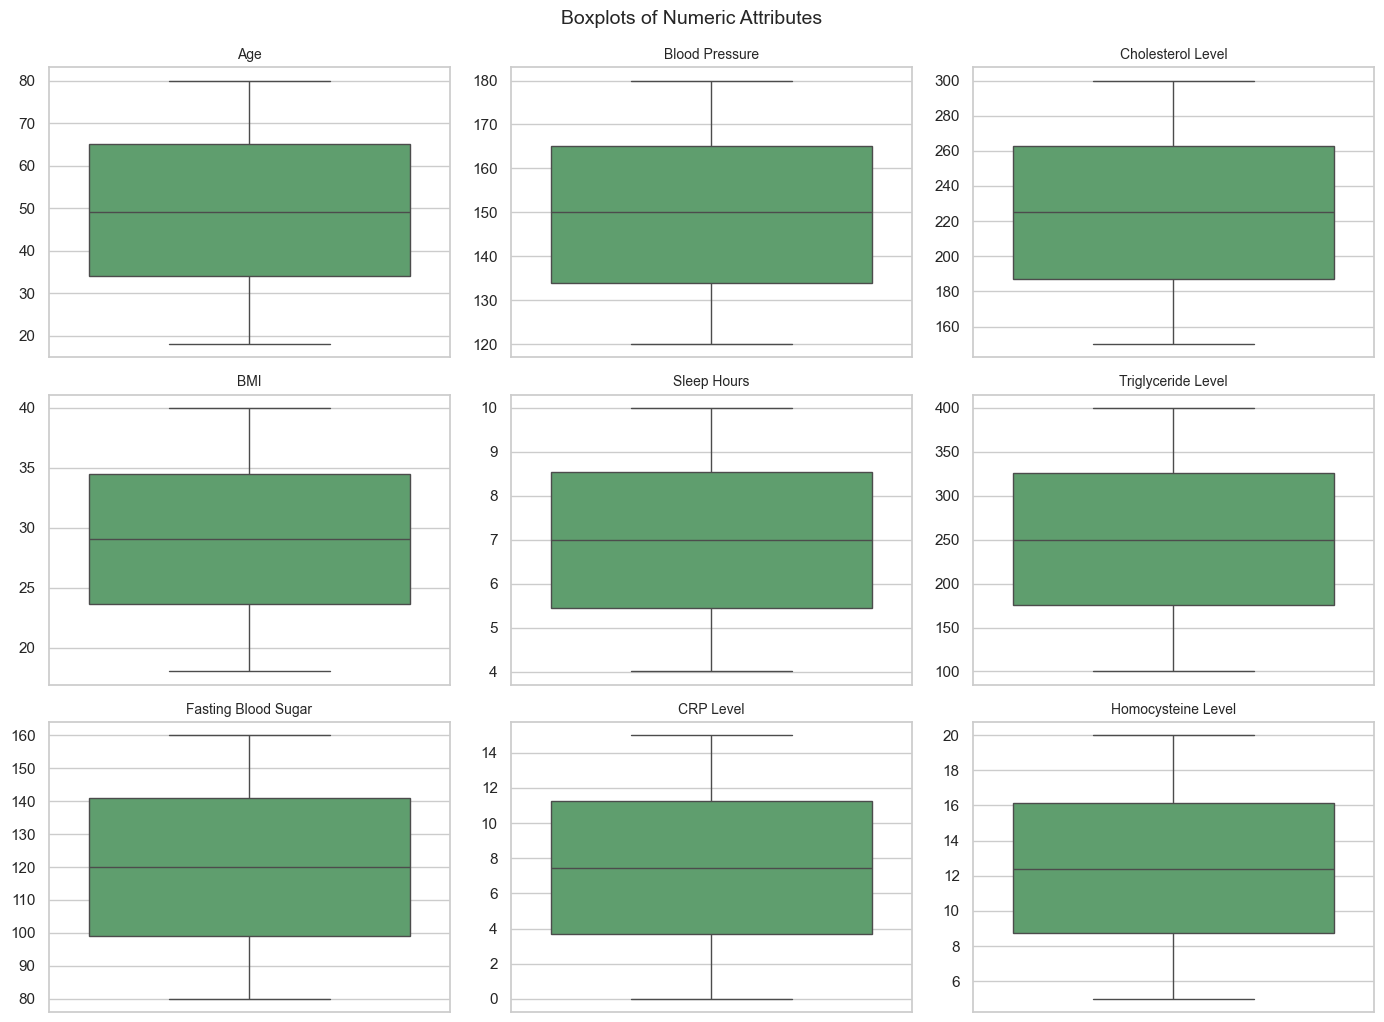

In [16]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.flatten(), NUMERIC_COLS):
    sns.boxplot(y=df_clean[col], ax=ax, color='#55A868')
    ax.set_title(col, fontsize=10)
    ax.set_ylabel('')
plt.tight_layout()
plt.suptitle('Boxplots of Numeric Attributes', y=1.02, fontsize=14)
plt.show()

In [17]:
outlier_counts = {}
for col in NUMERIC_COLS:
    q1, q3 = df_clean[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()
    outlier_counts[col] = n_out

pd.Series(outlier_counts, name='n_outliers_IQR').to_frame()

,n_outliers_IQR
Age,0
Blood Pressure,0
Cholesterol Level,0
BMI,0
Sleep Hours,0
Triglyceride Level,0
Fasting Blood Sugar,0
CRP Level,0
Homocysteine Level,0


**No outliers** are detected (by the IQR rule) in any of the 9 numeric attributes — every attribute is bounded within a plausible clinical range with no extreme values. No rows need to be removed for this reason.

### 3.2 Near-Constant / Highly Imbalanced Categorical Attributes

An attribute with (almost) only one value carries no information for a classifier and can be dropped.

In [18]:
for col in CATEGORICAL_COLS:
    vc = df_clean[col].value_counts(normalize=True)
    top_share = vc.iloc[0]
    flag = "  <-- near-constant, consider dropping" if top_share > 0.95 else ""
    print(f"{col:<22s}: {dict(vc.round(3))}{flag}")

Gender                : {'Female': np.float64(0.5), 'Male': np.float64(0.5)}
Exercise Habits       : {'High': np.float64(0.339), 'Medium': np.float64(0.333), 'Low': np.float64(0.328)}
Smoking               : {'Yes': np.float64(0.513), 'No': np.float64(0.487)}
Family Heart Disease  : {'No': np.float64(0.502), 'Yes': np.float64(0.498)}
Diabetes              : {'No': np.float64(0.505), 'Yes': np.float64(0.495)}
High Blood Pressure   : {'Yes': np.float64(0.501), 'No': np.float64(0.499)}
Low HDL Cholesterol   : {'Yes': np.float64(0.502), 'No': np.float64(0.498)}
High LDL Cholesterol  : {'No': np.float64(0.507), 'Yes': np.float64(0.493)}
Alcohol Consumption   : {'Unknown': np.float64(0.259), 'Medium': np.float64(0.251), 'Low': np.float64(0.249), 'High': np.float64(0.242)}
Stress Level          : {'Medium': np.float64(0.339), 'Low': np.float64(0.333), 'High': np.float64(0.328)}
Sugar Consumption     : {'Low': np.float64(0.34), 'High': np.float64(0.333), 'Medium': np.float64(0.327)}


No categorical attribute is dominated by a single value (every category keeps a reasonable share), so **no attribute is dropped for low variance**.

### 3.3 Multicollinearity Check (numeric attributes)

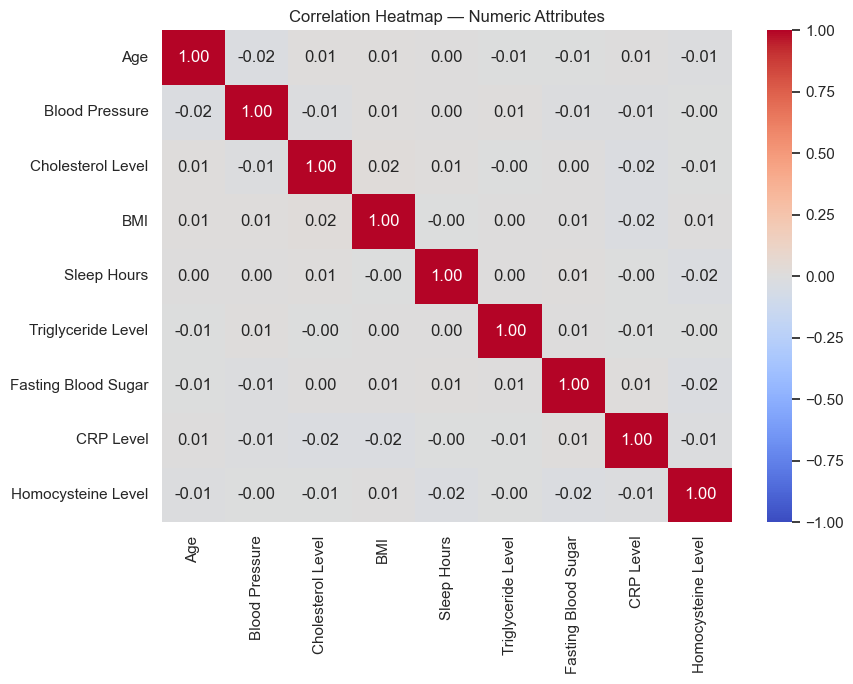

In [19]:
corr_matrix = df_clean[NUMERIC_COLS].corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax)
ax.set_title('Correlation Heatmap — Numeric Attributes')
plt.tight_layout()
plt.show()

In [20]:
corr_abs = corr_matrix.abs().to_numpy().copy()
np.fill_diagonal(corr_abs, 0)
print(f"Maximum pairwise correlation among numeric attributes: {corr_abs.max():.3f}")

Maximum pairwise correlation among numeric attributes: 0.023


The strongest pairwise correlation among the 9 numeric attributes is only **~0.02** — there is effectively **no multicollinearity**. No numeric attribute is redundant, so **all 9 are kept**.

## 4. Data Transformation

Unlike classic scikit-learn pipelines (which require numeric input and therefore label/one-hot encoding for categorical attributes), **Weka's ARFF format supports nominal attributes natively**. We therefore keep every categorical attribute as a nominal string — no encoding is needed, and the result stays directly human-readable for the report.

The only transformation we apply is **renaming columns** (replacing spaces with underscores), so the attribute names are safe to reference from the Java/Weka code that Person 2 and Person 3 will write (no quoting needed around attribute names).

In [21]:
df_clean.columns = [c.replace(' ', '_') for c in df_clean.columns]

NUMERIC_COLS = [c.replace(' ', '_') for c in NUMERIC_COLS]
CATEGORICAL_COLS = [c.replace(' ', '_') for c in CATEGORICAL_COLS]
TARGET_COL = TARGET_COL.replace(' ', '_')

df_clean.columns.tolist()

['Age',
 'Gender',
 'Blood_Pressure',
 'Cholesterol_Level',
 'Exercise_Habits',
 'Smoking',
 'Family_Heart_Disease',
 'Diabetes',
 'BMI',
 'High_Blood_Pressure',
 'Low_HDL_Cholesterol',
 'High_LDL_Cholesterol',
 'Alcohol_Consumption',
 'Stress_Level',
 'Sleep_Hours',
 'Sugar_Consumption',
 'Triglyceride_Level',
 'Fasting_Blood_Sugar',
 'CRP_Level',
 'Homocysteine_Level',
 'Heart_Disease_Status']

## 5. Data Analysis

### 5.1 Target Variable Distribution

Heart_Disease_Status
No     7621
Yes    1911
Name: count, dtype: int64
Heart_Disease_Status
No     79.95
Yes    20.05
Name: proportion, dtype: float64


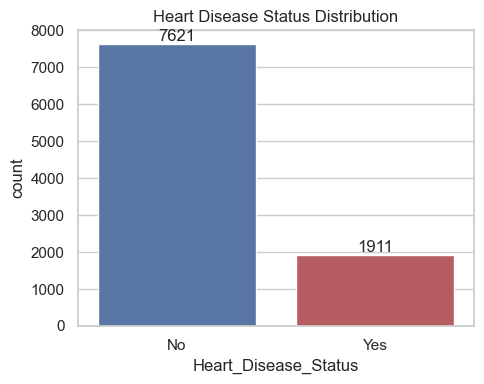

In [22]:
target_counts = df_clean[TARGET_COL].value_counts()
target_pct = df_clean[TARGET_COL].value_counts(normalize=True).round(4) * 100
print(target_counts)
print(target_pct)

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(x=df_clean[TARGET_COL], order=['No', 'Yes'], palette=['#4C72B0', '#C44E52'], ax=ax)
ax.set_title('Heart Disease Status Distribution')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom')
plt.tight_layout()
plt.show()

The label is **imbalanced (~80% No / ~20% Yes)**. This has two practical consequences for later steps:
- The train/test split must be **stratified** so both sets keep this ratio (handled in Section 6).
- At evaluation time (Step 4, Person 3), **accuracy alone is misleading**: a trivial classifier that always predicts `"No"` would already score ~80% accuracy. **Precision, Recall and F1 of the `"Yes"` class** should be reported alongside accuracy.

### 5.2 Distribution of Numeric Attributes

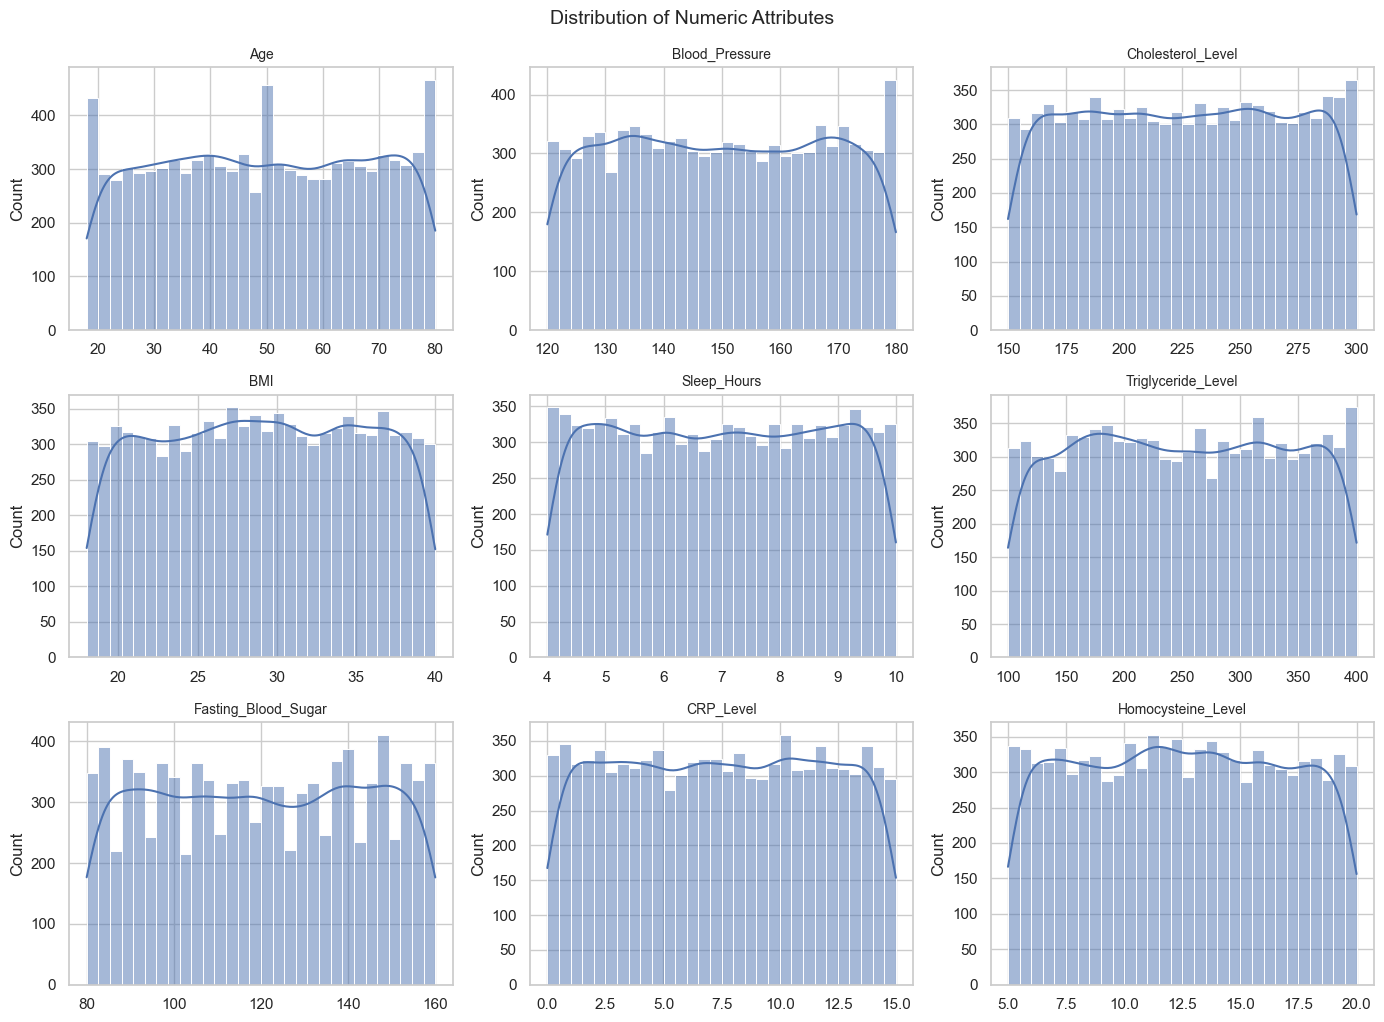

In [23]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.flatten(), NUMERIC_COLS):
    sns.histplot(df_clean[col], bins=30, kde=True, ax=ax, color='#4C72B0')
    ax.set_title(col, fontsize=10)
    ax.set_xlabel('')
plt.tight_layout()
plt.suptitle('Distribution of Numeric Attributes', y=1.02, fontsize=14)
plt.show()

All 9 numeric attributes look roughly uniform/near-normal, with no heavy skew and no extreme tails — consistent with the "no outliers" finding in Section 3.1.

### 5.3 Numeric Attributes vs. Target

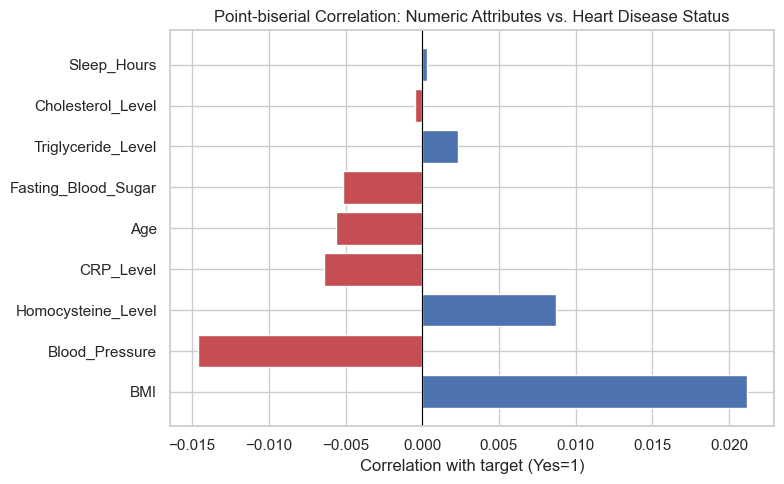

,correlation
BMI,0.021139
Blood_Pressure,-0.014643
Homocysteine_Level,0.008731
CRP_Level,-0.006405
Age,-0.005652
Fasting_Blood_Sugar,-0.005172
Triglyceride_Level,0.002314
Cholesterol_Level,-0.000481
Sleep_Hours,0.000302


In [24]:
df_clean['_target_bin'] = (df_clean[TARGET_COL] == 'Yes').astype(int)

point_biserial = df_clean[NUMERIC_COLS].corrwith(df_clean['_target_bin']).sort_values(key=abs, ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
colors = ['#C44E52' if v < 0 else '#4C72B0' for v in point_biserial.values]
ax.barh(point_biserial.index, point_biserial.values, color=colors)
ax.set_xlabel('Correlation with target (Yes=1)')
ax.set_title('Point-biserial Correlation: Numeric Attributes vs. Heart Disease Status')
ax.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

point_biserial.to_frame('correlation')

In [25]:
# Independent t-test: is the mean of each numeric attribute different between
# the "Yes" and "No" groups?
ttest_rows = []
for col in NUMERIC_COLS:
    yes_vals = df_clean.loc[df_clean[TARGET_COL] == 'Yes', col]
    no_vals = df_clean.loc[df_clean[TARGET_COL] == 'No', col]
    t_stat, p_val = stats.ttest_ind(yes_vals, no_vals, equal_var=False)
    ttest_rows.append({'attribute': col, 'mean_Yes': yes_vals.mean(), 'mean_No': no_vals.mean(),
                        't_stat': t_stat, 'p_value': p_val,
                        'significant_at_0.05': p_val < 0.05})

ttest_df = pd.DataFrame(ttest_rows).sort_values('p_value')
ttest_df

,attribute,mean_Yes,mean_No,t_stat,p_value,significant_at_0.05
3,BMI,29.323335,28.991043,2.067294,0.038794,True
1,Blood_Pressure,149.279435,149.922320,-1.436902,0.150852,False
8,Homocysteine_Level,12.523942,12.429762,0.850178,0.395296,False
7,CRP_Level,7.406676,7.476157,-0.629041,0.529371,False
0,Age,49.120356,49.377378,-0.554562,0.579236,False
6,Fasting_Blood_Sugar,119.855573,120.160478,-0.506870,0.612284,False
5,Triglyceride_Level,250.790686,250.287233,0.225226,0.821819,False
2,Cholesterol_Level,225.246468,225.298911,-0.047266,0.962305,False
4,Sleep_Hours,6.990297,6.988975,0.029427,0.976526,False


**Finding:** correlations between every numeric attribute and the target are very weak (**|r| < 0.03** for all 9 attributes), and the independent t-tests confirm this — **none of the numeric attributes show a statistically significant mean difference between the "Yes" and "No" groups at the 0.05 level**. No single numeric attribute is, by itself, a useful linear predictor of heart disease in this dataset.

### 5.4 Categorical Attributes vs. Target

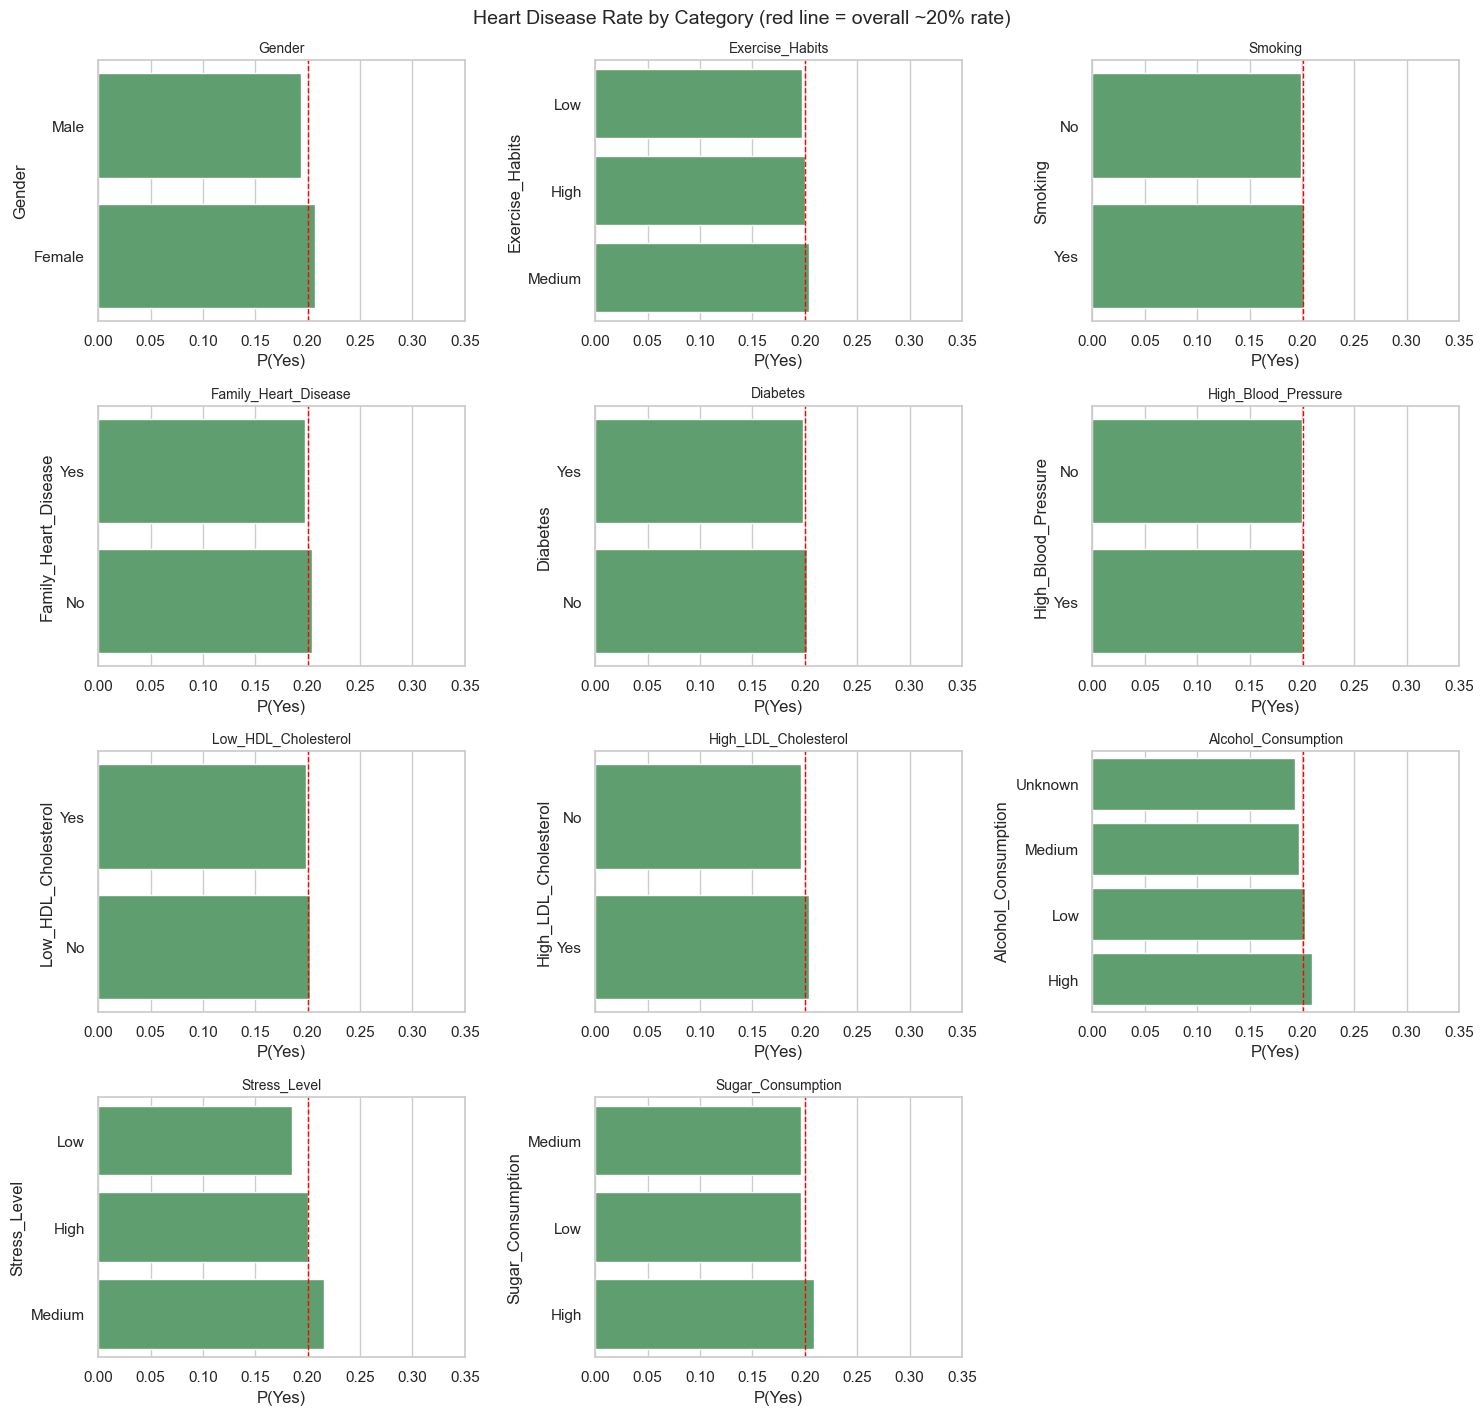

In [26]:
fig, axes = plt.subplots(4, 3, figsize=(15, 14))
for ax, col in zip(axes.flatten(), CATEGORICAL_COLS):
    rate = df_clean.groupby(col)['_target_bin'].mean().sort_values()
    sns.barplot(x=rate.values, y=rate.index, ax=ax, color='#55A868')
    ax.axvline(df_clean['_target_bin'].mean(), color='red', linestyle='--', linewidth=1,
               label='overall rate')
    ax.set_title(col, fontsize=10)
    ax.set_xlabel('P(Yes)')
    ax.set_xlim(0, 0.35)
axes.flatten()[-1].axis('off')
plt.tight_layout()
plt.suptitle('Heart Disease Rate by Category (red line = overall ~20% rate)', y=1.01, fontsize=14)
plt.show()

In [27]:
# Chi-square test of independence: is each categorical attribute associated with the target?
chi2_rows = []
for col in CATEGORICAL_COLS:
    contingency = pd.crosstab(df_clean[col], df_clean[TARGET_COL])
    chi2, p_val, dof, _ = stats.chi2_contingency(contingency)
    chi2_rows.append({'attribute': col, 'chi2': chi2, 'dof': dof, 'p_value': p_val,
                       'significant_at_0.05': p_val < 0.05})

chi2_df = pd.DataFrame(chi2_rows).sort_values('p_value')
chi2_df

,attribute,chi2,dof,p_value,significant_at_0.05
9,Stress_Level,9.168116,2,0.010213,True
0,Gender,2.782153,1,0.095320,False
10,Sugar_Consumption,2.224623,2,0.328798,False
7,High_LDL_Cholesterol,0.795492,1,0.372445,False
3,Family_Heart_Disease,0.669414,1,0.413256,False
8,Alcohol_Consumption,2.216398,3,0.528726,False
4,Diabetes,0.183830,1,0.668102,False
6,Low_HDL_Cholesterol,0.151662,1,0.696952,False
2,Smoking,0.126249,1,0.722354,False
1,Exercise_Habits,0.402606,2,0.817665,False


**Finding:** for every categorical attribute, the disease rate across categories stays close to the overall ~20% baseline, and the chi-square tests show **no statistically significant association** between any single categorical attribute and the target at the 0.05 level.

### 5.5 Summary of Data Analysis

- The dataset is **clean** (0 duplicates; all missing values resolved) and has **no outliers** in its numeric attributes.
- There is **no multicollinearity** between numeric attributes (max |r| ≈ 0.02), so all 9 are kept.
- **No single attribute — numeric or categorical — shows a statistically significant relationship with `Heart Disease Status`** on its own (all correlations |r| < 0.03; all t-tests and chi-square tests non-significant at α = 0.05).
- This means Person 2's and Person 3's models will have to rely on **non-linear / multi-attribute interactions** (which tree-based methods like Decision Tree and Random Forest can capture, unlike plain linear/logistic models) — and, given the ~80/20 class imbalance, **evaluation must go beyond Accuracy** to Precision/Recall/F1 for the `"Yes"` class, since a trivial majority-class predictor already reaches ~80% accuracy without learning anything.

## 6. Train/Test Split

We use a **stratified 80/20 split** so both sets preserve the ~80/20 class ratio, with a fixed random seed so Person 2 and Person 3 can reproduce the exact same split.

In [28]:
feature_cols = [c for c in df_clean.columns if c not in (TARGET_COL, '_target_bin')]

train_df, test_df = train_test_split(
    df_clean[feature_cols + [TARGET_COL]],
    test_size=0.2,
    random_state=RANDOM_SEED,
    stratify=df_clean[TARGET_COL]
)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(f"Train set: {train_df.shape}")
print(f"Test set:  {test_df.shape}")
print()
print("Class ratio — train:")
print(train_df[TARGET_COL].value_counts(normalize=True).round(4))
print()
print("Class ratio — test:")
print(test_df[TARGET_COL].value_counts(normalize=True).round(4))

Train set: (7625, 21)
Test set:  (1907, 21)

Class ratio — train:
Heart_Disease_Status
No     0.7995
Yes    0.2005
Name: proportion, dtype: float64

Class ratio — test:
Heart_Disease_Status
No     0.7997
Yes    0.2003
Name: proportion, dtype: float64


## 7. Export for Modeling

We export three files into `code/dataset/` (sibling of `code/src/`), alongside the raw `heart_disease.csv`, matching the project's submission layout:
- `cleaned_heart_disease.csv` — full cleaned dataset (for reference / further EDA)
- `train.arff`, `test.arff` — ready for Person 2 (J48) and Person 3 (Random Forest) to load directly in Java/Weka

Nominal attribute domains (the `{...}` category lists in the ARFF header) are computed from the **full cleaned dataset**, not from each split separately — this guarantees the train and test ARFF files declare identical categories even if a rare category happens to be absent from one split.

In [29]:
# Writes directly into code/dataset/ (sibling of code/src/), next to heart_disease.csv,
# instead of a separate output/ subfolder -- matching the required submission layout.
OUT_DIR = "../dataset"
os.makedirs(OUT_DIR, exist_ok=True)

df_clean.drop(columns=['_target_bin']).to_csv(os.path.join(OUT_DIR, "cleaned_heart_disease.csv"), index=False)
print("Saved:", os.path.join(OUT_DIR, "cleaned_heart_disease.csv"))

Saved: ../dataset\cleaned_heart_disease.csv


In [30]:
def write_arff(data: pd.DataFrame, relation_name: str, out_path: str,
               numeric_cols, categorical_cols, target_col, nominal_domains: dict):
    """Write a pandas DataFrame to a Weka-compatible ARFF file.
    The target column is written LAST, which matches Weka's default class index
    (data.setClassIndex(data.numAttributes() - 1) in Java).
    """
    ordered_cols = numeric_cols + categorical_cols + [target_col]
    with open(out_path, 'w') as f:
        f.write(f"@RELATION {relation_name}\n\n")
        for col in ordered_cols:
            if col in numeric_cols:
                f.write(f"@ATTRIBUTE {col} NUMERIC\n")
            else:
                cats = nominal_domains[col]
                f.write(f"@ATTRIBUTE {col} {{{','.join(cats)}}}\n")
        f.write("\n@DATA\n")
        for _, row in data.iterrows():
            f.write(",".join(str(row[c]) for c in ordered_cols) + "\n")
    print(f"Saved: {out_path}  ({len(data)} instances)")

nominal_domains = {c: sorted(df_clean[c].unique().tolist()) for c in CATEGORICAL_COLS}
nominal_domains[TARGET_COL] = sorted(df_clean[TARGET_COL].unique().tolist())

write_arff(train_df, "heart_disease_train", os.path.join(OUT_DIR, "train.arff"),
           NUMERIC_COLS, CATEGORICAL_COLS, TARGET_COL, nominal_domains)
write_arff(test_df, "heart_disease_test", os.path.join(OUT_DIR, "test.arff"),
           NUMERIC_COLS, CATEGORICAL_COLS, TARGET_COL, nominal_domains)

Saved: ../dataset\train.arff  (7625 instances)
Saved: ../dataset\test.arff  (1907 instances)


In [31]:
# Sanity check: confirm the ARFF files are well-formed by reading them back
for fname in ["train.arff", "test.arff"]:
    data, meta = arff_reader.loadarff(os.path.join(OUT_DIR, fname))
    print(f"{fname}: loaded OK, {len(data)} instances, {len(meta.names())} attributes")

train.arff: loaded OK, 7625 instances, 21 attributes
test.arff: loaded OK, 1907 instances, 21 attributes


In [32]:
with open(os.path.join(OUT_DIR, "train.arff")) as f:
    preview_lines = [next(f) for _ in range(25)]
print("".join(preview_lines))

@RELATION heart_disease_train

@ATTRIBUTE Age NUMERIC
@ATTRIBUTE Blood_Pressure NUMERIC
@ATTRIBUTE Cholesterol_Level NUMERIC
@ATTRIBUTE BMI NUMERIC
@ATTRIBUTE Sleep_Hours NUMERIC
@ATTRIBUTE Triglyceride_Level NUMERIC
@ATTRIBUTE Fasting_Blood_Sugar NUMERIC
@ATTRIBUTE CRP_Level NUMERIC
@ATTRIBUTE Homocysteine_Level NUMERIC
@ATTRIBUTE Gender {Female,Male}
@ATTRIBUTE Exercise_Habits {High,Low,Medium}
@ATTRIBUTE Smoking {No,Yes}
@ATTRIBUTE Family_Heart_Disease {No,Yes}
@ATTRIBUTE Diabetes {No,Yes}
@ATTRIBUTE High_Blood_Pressure {No,Yes}
@ATTRIBUTE Low_HDL_Cholesterol {No,Yes}
@ATTRIBUTE High_LDL_Cholesterol {No,Yes}
@ATTRIBUTE Alcohol_Consumption {High,Low,Medium,Unknown}
@ATTRIBUTE Stress_Level {High,Low,Medium}
@ATTRIBUTE Sugar_Consumption {High,Low,Medium}
@ATTRIBUTE Heart_Disease_Status {No,Yes}

@DATA



## 8. Conclusion — Step 1 Summary

| Step | Decision | Result |
|---|---|---|
| Duplicates | Checked | 0 found |
| Missing values (`Alcohol Consumption`) | Recoded as `"Unknown"` category | 0 rows lost |
| Missing values (all other columns) | Dropped affected rows | 468 rows dropped (4.68%); class ratio unchanged (≈80/20) |
| Outliers (IQR, 9 numeric attributes) | Checked | 0 outliers found — no rows removed |
| Near-constant categorical attributes | Checked | None found — all 11 kept |
| Multicollinearity (numeric attributes) | Checked | Max |r| ≈ 0.02 — all 9 kept |
| Attribute naming | Renamed (spaces → underscores) | ARFF/Weka-safe names |
| Target vs. every attribute | Correlation / t-test / chi-square | No attribute is individually significant — flag for Step 3/4 |
| Train/test split | Stratified 80/20, seed=42 | Train 7,625 / Test 1,907 rows |
| Export | `cleaned_heart_disease.csv`, `train.arff`, `test.arff` | Ready for Person 2 & Person 3 |

**Final cleaned dataset:** 9,532 rows × 21 columns (20 attributes + target), 0 missing values, 0 duplicates.

**Hand-off note for Person 2 & Person 3:** both `train.arff` and `test.arff` place `Heart_Disease_Status` as the **last attribute**, so `data.setClassIndex(data.numAttributes() - 1)` in Java will select the correct class. Please use these exact files (do not re-split the data independently) so that both algorithms are compared on identical train/test data in Step 4.